# Insight จาก CCTV และข้อมูลที่ web scraping เก็บไว้

วิเคราะห์ไฟล์ที่ส่งมา **60,230 ภาพ จาก 100 กล้อง วันที่ 25–31 สิงหาคม 2026**
เพิ่มคอลัมน์จากการคำนวณและข้อมูลภายนอก พร้อม aggregate รายวัน ชั่วโมง กล้อง สภาพฝน และประเภทถนน

**วิธีใช้:** เลือก kernel `dsde` แล้ว Run All จาก root หรือโฟลเดอร์ใดก็ได้ภายในโปรเจกต์
ผลลัพธ์อยู่ใน `outputs/cctv_20261128/` และทุกขั้นตอนใช้ข้อมูลที่เก็บไว้ในเครื่อง
หน่วยหลักคือ **จำนวนรถที่ตรวจพบต่อภาพ = car + motor + truck + bus**
รถคันเดิมอาจปรากฏหลายภาพ จึงใช้ผลนี้อธิบายภาพที่สังเกตได้ ไม่ใช่จำนวนรถผ่านไม่ซ้ำ

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image

working_dir = Path.cwd().resolve()
repo = next((base for base in (working_dir, *working_dir.parents)
             if (base / "DataSci/analysis/scraped_insights.py").is_file()), None)
if repo is None:
    raise FileNotFoundError("Open this notebook from within the project.")
analysis_dir = repo / "DataSci/analysis"
if str(analysis_dir) not in sys.path:
    sys.path.insert(0, str(analysis_dir))
from scraped_insights import (
    run_analysis, add_features, summarize, matched_comparison, CLASSES, MOTOR_CLASSES,
)
output_dir = analysis_dir / "outputs/cctv_20261128"
source_path = output_dir / "input_image_counts.parquet"
if not source_path.exists():
    source_path = Path.home() / "Downloads/image_counts.parquet"
source = pd.read_parquet(source_path)
# Rebuild all derived columns, aggregations, the report and the plot.
df, tables, quality = run_analysis(source_path, output_dir)
pd.set_option("display.max_columns", 12)
print(f"Rows: {len(df):,} | Source columns: {len(source.columns)} | Enriched columns: {len(df.columns)}")
print(f"Cameras: {df.camera_id.nunique()} | Dates: {df.date_local.nunique()}")
print(f"Output: {output_dir}")

Rows: 60,230 | Source columns: 10 | Enriched columns: 51
Cameras: 100 | Dates: 7
Output: D:\DataSci\Datasci_Bangkok-CCTV-Image-Analysis\DataSci\analysis\outputs\cctv_20261128


In [2]:
df

,camera_id,ts_filename,filename,car,motor,truck,...,is_commute_window,clock_day_night,brightness_clock_disagree,rain_band,camera_mean_motor_vehicles,relative_to_camera_mean
0,1028,2026-08-25 06:10:12+07:00,1028_แยกสะพานแดง_แยกสะพานแดง_20260825_061012.jpg,3,2,0,...,True,day,False,dry_0,7.156250,0.698690
1,1028,2026-08-25 06:21:00+07:00,1028_แยกสะพานแดง_แยกสะพานแดง_20260825_062100.jpg,6,4,1,...,True,day,False,dry_0,7.156250,1.676856
2,1028,2026-08-25 06:31:15+07:00,1028_แยกสะพานแดง_แยกสะพานแดง_20260825_063115.jpg,4,1,0,...,True,day,False,dry_0,7.156250,0.838428
3,1028,2026-08-25 06:40:54+07:00,1028_แยกสะพานแดง_แยกสะพานแดง_20260825_064054.jpg,0,7,1,...,True,day,False,dry_0,7.156250,1.117904
4,1028,2026-08-25 06:50:53+07:00,1028_แยกสะพานแดง_แยกสะพานแดง_20260825_065053.jpg,6,6,0,...,True,day,False,dry_0,7.156250,1.676856
...,...,...,...,...,...,...,...,...,...,...,...,...,...
60225,939,2026-08-31 20:15:07+07:00,939_TF-KP-04-แยกมหาดไทย_แยกมหาดไทย_20260831_20...,4,0,0,...,False,night,False,positive_lt1,8.787402,0.455197
60226,939,2026-08-31 20:25:06+07:00,939_TF-KP-04-แยกมหาดไทย_แยกมหาดไทย_20260831_20...,8,0,3,...,False,night,False,positive_lt1,8.787402,1.251792
60227,939,2026-08-31 20:35:06+07:00,939_TF-KP-04-แยกมหาดไทย_แยกมหาดไทย_20260831_20...,9,0,1,...,False,night,False,positive_lt1,8.787402,1.137993
60228,939,2026-08-31 20:45:06+07:00,939_TF-KP-04-แยกมหาดไทย_แยกมหาดไทย_20260831_20...,7,0,1,...,False,night,False,positive_lt1,8.787402,0.910394


## 1. ตรวจข้อมูลก่อนหา insight

คีย์ภาพคือ `camera_id + filename + ts_filename` การ join ต้องไม่เพิ่มแถว
คอลัมน์ต้นทางทั้ง 10 คอลัมน์ต้องคงค่าเดิม ตาราง coverage เทียบกับรายการภาพ Bronze ที่ scrape เก็บไว้
**ภาพที่ไม่มีผลนับไม่ใช่ภาพที่ไม่มีรถ** และ coverage นี้ไม่ใช่การวัดว่าภาพครบตลอด 24 ชั่วโมง

In [3]:
pd.testing.assert_frame_equal(df[source.columns], source.reset_index(drop=True), check_exact=True)
display(pd.Series({key: quality[key] for key in [
    "rows", "cameras", "dates", "source_columns", "enriched_columns",
    "duplicate_image_keys", "source_null_cells", "inventory_rows", "missing_counts",
    "inventory_coverage", "original_columns_unchanged", "aggregate_totals_reconciled",
]}, name="value").to_frame())
display(tables["coverage_daily"])

,value
rows,60230
cameras,100
dates,7
source_columns,10
enriched_columns,51
duplicate_image_keys,0
source_null_cells,0
inventory_rows,61319
missing_counts,1089
inventory_coverage,0.98224


,date_local,inventory_images,analyzed_images,missing_counts,coverage_fraction
0,2026-08-25,8937,8828,109,0.987804
1,2026-08-26,8953,8721,232,0.974087
2,2026-08-27,7438,7237,201,0.972977
3,2026-08-28,9015,8808,207,0.977038
4,2026-08-29,8964,8833,131,0.985386
5,2026-08-30,9002,8885,117,0.987003
6,2026-08-31,9010,8918,92,0.989789


## 2. เพิ่ม columns เพื่อวิเคราะห์ง่ายขึ้น

`motor_vehicles_total` รวมรถ 4 ประเภท ส่วน `vehicles_total` ที่โค้ดเดิมสร้างยังคงหมายถึง car + motor
เพิ่มสัดส่วนรถจักรยานยนต์/รถหนัก ช่วงเวลา เกณฑ์กลางวันตามนาฬิกา และจำนวนรถเทียบค่าเฉลี่ยของกล้อง
ถ้าไม่มีรถ สัดส่วนเป็น null เพราะหารด้วยศูนย์ไม่ได้

ข้อมูลภายนอกที่ join: ปฏิทินตามวันที่ไทย, OSM ตามกล้อง, อากาศตามกริดและชั่วโมง,
อุบัติเหตุตามชั่วโมงและระยะ 300 เมตร ส่วน BEM คงเป็นตารางรายเดือน
`relative_to_camera_mean` เป็นค่าพรรณนาจากข้อมูลทั้งชุด ต้องคำนวณใหม่จาก train เท่านั้นหากนำไปสร้างโมเดลทำนาย

In [4]:
# Examples of the feature formulas. Full definitions are in add_features().
feature_example = source.head(8).copy()
feature_example["motor_vehicles_total"] = feature_example[MOTOR_CLASSES].sum(axis=1)
feature_example["heavy_vehicles_total"] = feature_example.truck + feature_example.bus
denominator = feature_example.motor_vehicles_total.where(feature_example.motor_vehicles_total.ne(0))
feature_example["motor_share_all"] = feature_example.motor / denominator
display(feature_example[["camera_id", *MOTOR_CLASSES, "motor_vehicles_total", "heavy_vehicles_total", "motor_share_all"]])
dictionary = pd.read_csv(output_dir / "data_dictionary.csv")
display(dictionary.loc[~dictionary.source_column, ["column", "description_th", "null_rows"]])

,camera_id,car,motor,truck,bus,motor_vehicles_total,heavy_vehicles_total,motor_share_all
0,1028,3,2,0,0,5,0,0.400000
1,1028,6,4,1,1,12,2,0.333333
2,1028,4,1,0,1,6,1,0.166667
3,1028,0,7,1,0,8,1,0.875000
4,1028,6,6,0,0,12,0,0.500000
5,1028,5,4,1,0,10,1,0.400000
6,1028,4,4,0,0,8,0,0.500000
7,1028,1,6,1,1,9,2,0.666667


,column,description_th,null_rows
10,vehicles_total,สูตรเดิม car + motor เท่านั้น; รายงานใหม่ใช้ m...,0
11,motor_share,สูตรเดิม motor / (car + motor); เป็น null เมื่...,1001
12,date_local,วันที่ไทยสำหรับเชื่อมปฏิทินและ aggregate รายวัน,0
13,hour_local,ชั่วโมงไทย 0–23,0
14,hour_start,เวลาต้นชั่วโมงไทย,0
15,rain_interval_end,hour_start + 1 ชั่วโมง; ฝนที่ประทับเวลาปลายช่ว...,0
16,day_of_week,ชื่อวันจากปฏิทินที่เก็บไว้,0
17,is_weekend,เสาร์หรืออาทิตย์,0
18,is_holiday,วันหยุดตามไฟล์ปฏิทิน; สถานะตรวจยืนยันทางการยัง...,0
19,day_type,public_holiday ก่อน weekend และ weekday ตามลำดับ,0


## 3. ใช้ groupby + agg เปรียบเทียบวันและเวลา

แสดงทั้งจำนวนภาพ ค่าเฉลี่ย median และ p90 เพราะแต่ละกลุ่มมีจำนวนภาพต่างกัน
สัดส่วน aggregate ใช้ **ผลรวมตัวเศษ / ผลรวมตัวส่วน** และค่าเฉลี่ยรวมใช้จำนวนภาพเป็นน้ำหนัก
`day_type` มาจากปฏิทินที่เก็บไว้ ส่วนวันในสัปดาห์คำนวณจาก timestamp

In [5]:
# A transparent groupby/agg example; exported summaries include all six classes.
daily_agg = df.groupby(["date_local", "day_type"], as_index=False).agg(
    images=("filename", "size"),
    cameras=("camera_id", "nunique"),
    total_detections=("motor_vehicles_total", "sum"),
    mean_motor_vehicles=("motor_vehicles_total", "mean"),
    median_motor_vehicles=("motor_vehicles_total", "median"),
    p90_motor_vehicles=("motor_vehicles_total", lambda x: x.quantile(0.9)),
)
assert daily_agg.images.sum() == len(df)
assert daily_agg.total_detections.sum() == df.motor_vehicles_total.sum()
display(daily_agg)
summary_columns = ["day_type", "images", "cameras", "dates", "mean_motor_vehicles", "motor_share_all", "heavy_vehicle_share"]
display(tables["day_type"][summary_columns])

,date_local,day_type,images,cameras,total_detections,mean_motor_vehicles,median_motor_vehicles,p90_motor_vehicles
0,2026-08-25,weekday,8828,100,108635,12.305732,11.0,23.0
1,2026-08-26,weekday,8721,100,110606,12.682720,11.0,24.0
2,2026-08-27,weekday,7237,99,88297,12.200774,11.0,23.0
3,2026-08-28,weekday,8808,100,111632,12.673933,11.0,24.0
4,2026-08-29,weekend,8833,100,92109,10.427827,9.0,20.0
5,2026-08-30,weekend,8885,100,83724,9.423073,8.0,18.0
6,2026-08-31,weekday,8918,100,106485,11.940458,10.5,23.0


,day_type,images,cameras,dates,mean_motor_vehicles,motor_share_all,heavy_vehicle_share
0,weekday,42512,100,5,12.364862,0.258692,0.085830
1,weekend,17718,100,2,9.923976,0.219720,0.081373


day_type,weekday,weekend
hour_local,,
6,10.006628,5.571669
7,14.000484,7.505495
8,13.868699,9.590786
9,12.651500,10.611438
10,12.204061,11.211409
11,12.547418,12.176068
12,12.559052,12.475382
13,12.371918,11.806397
14,12.697966,11.761106


,time_period,day_type,images,mean_motor_vehicles
0,daytime_09_16,weekday,20667,12.626651
1,daytime_09_16,weekend,8296,11.491201
2,evening_16_19,weekday,8878,14.218405
3,evening_16_19,weekend,3556,10.623735
4,late_19_22,weekday,6180,8.545307
5,late_19_22,weekend,2481,6.974204
6,morning_06_09,weekday,6787,12.621040
7,morning_06_09,weekend,3385,7.509897


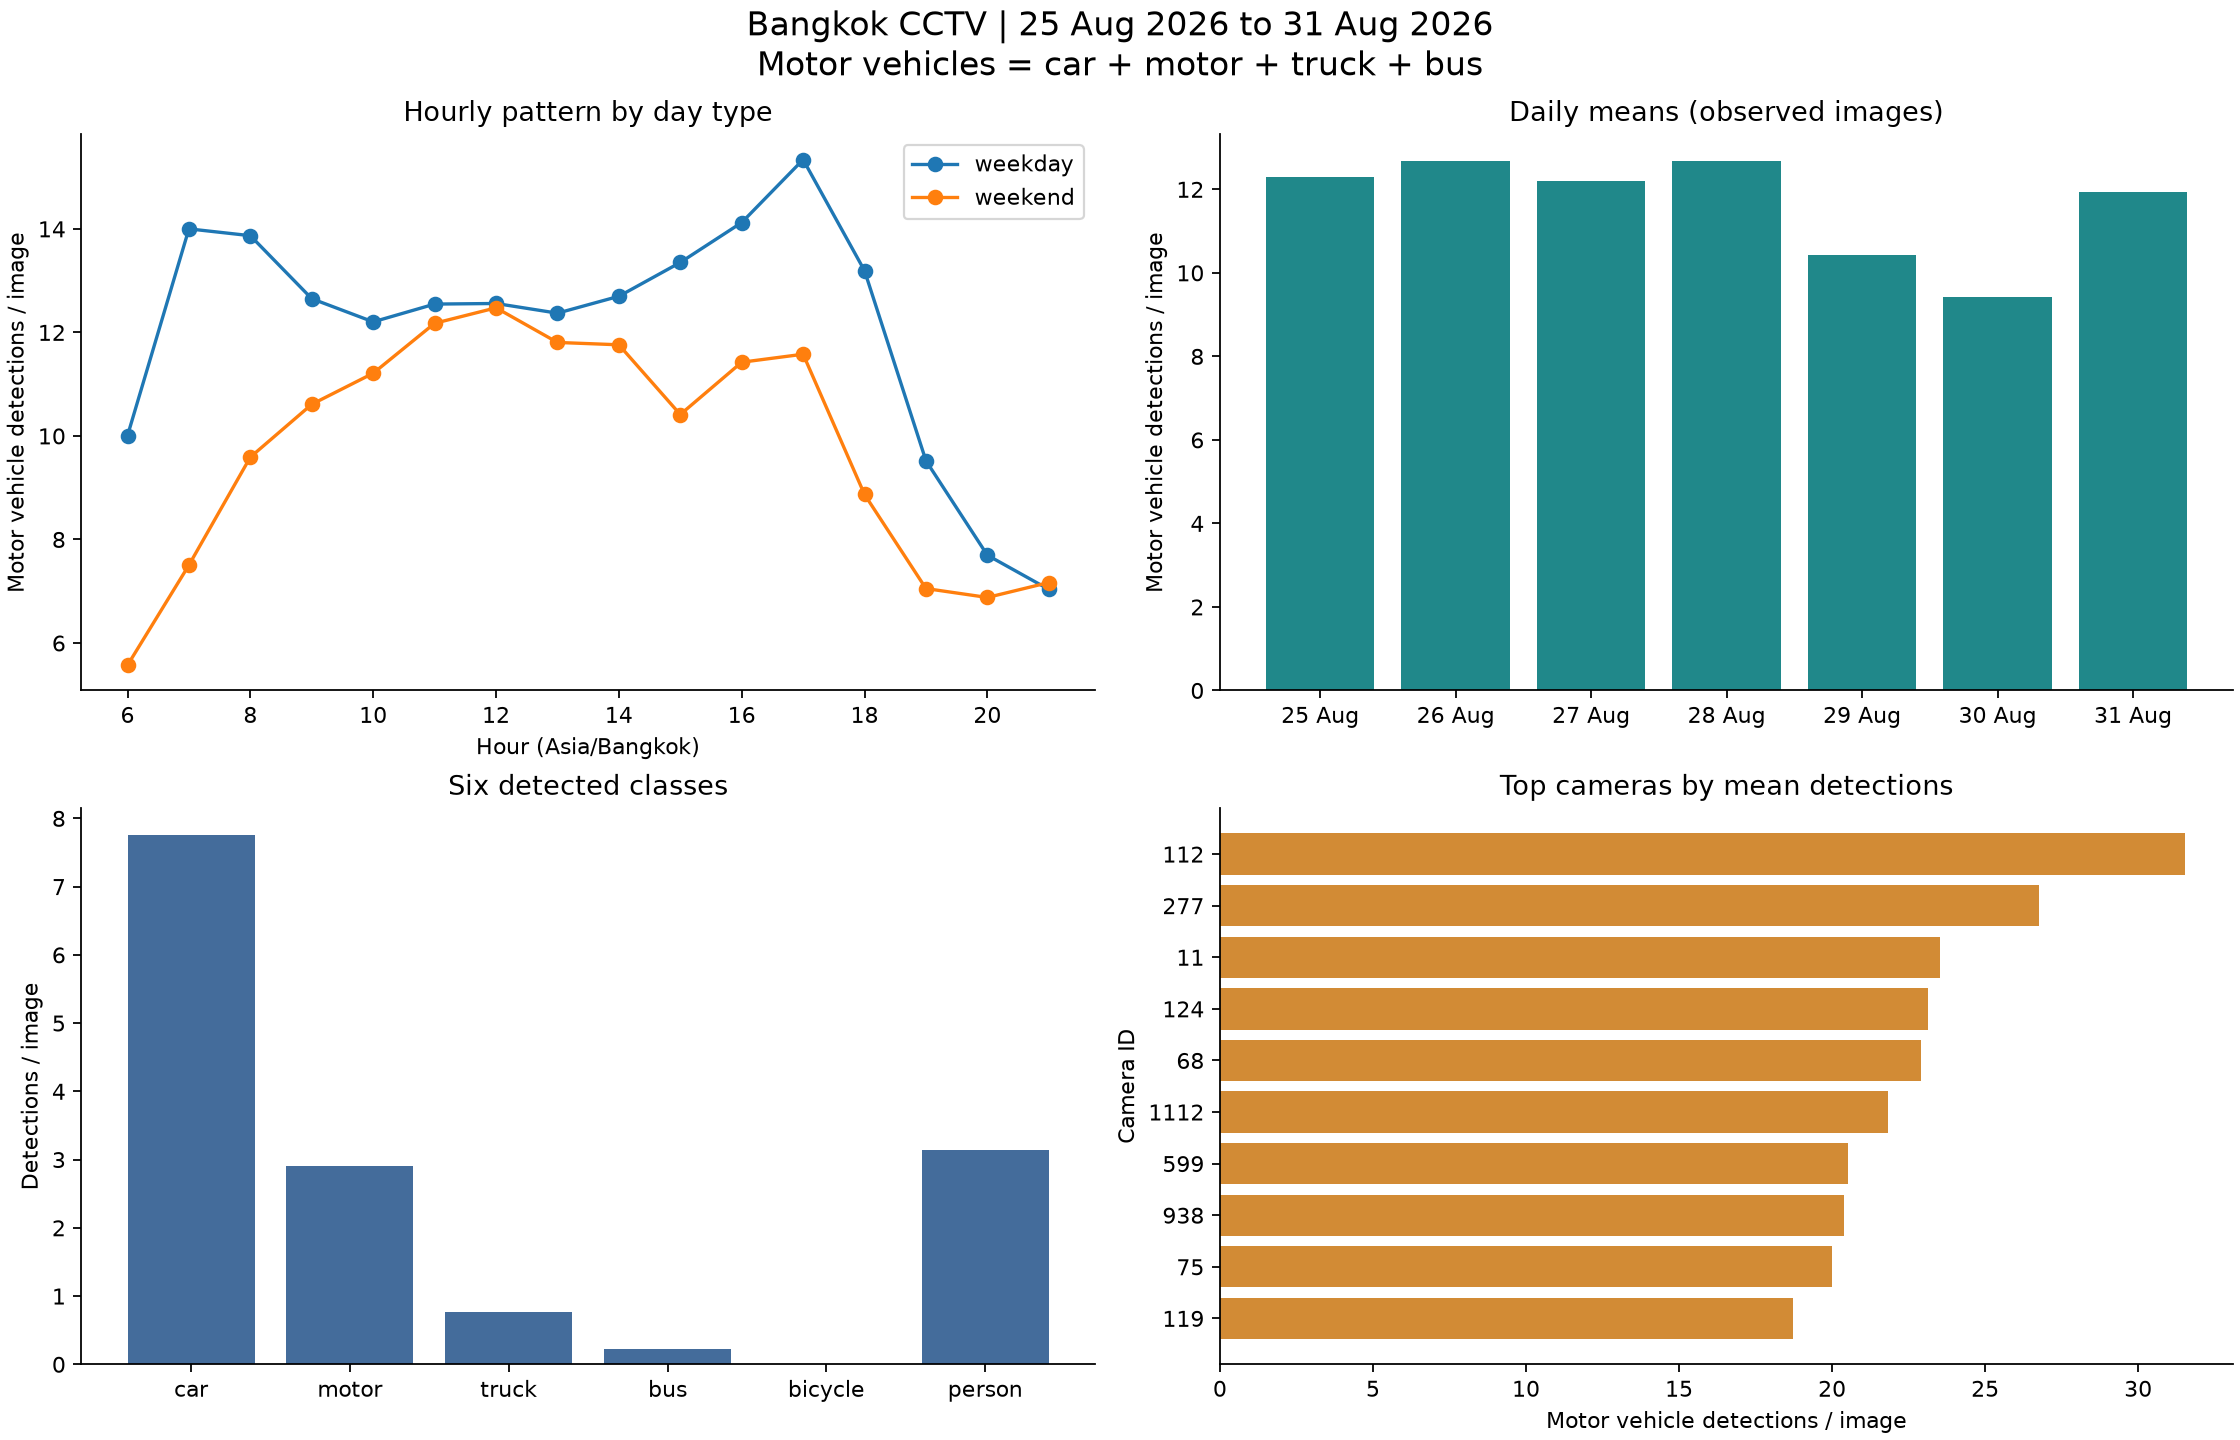

In [6]:
hourly = tables["hourly"]
display(hourly.pivot(index="hour_local", columns="day_type", values="mean_motor_vehicles"))
display(tables["time_period"][["time_period", "day_type", "images", "mean_motor_vehicles"]])
display(Image(filename=str(output_dir / "overview.png"), width=1100))

## 4. ฝนสัมพันธ์กับการตรวจพบรถอย่างไร

ดูทั้งการรวมทุกภาพและการเทียบ **กล้องเดียวกัน + ชั่วโมงเดียวกัน + ประเภทวันเดียวกัน**
กลุ่มที่จับคู่ต้องมีอย่างน้อย 3 ภาพในแต่ละสภาพ แล้วเฉลี่ยผลต่างโดยให้ทุกคู่กลุ่มน้ำหนักเท่ากัน
วิธีนี้ลดความต่างขององค์ประกอบกลุ่มบางส่วน แต่ยังไม่ใช่หลักฐานเชิงเหตุและผล

[นิยาม Open-Meteo](https://open-meteo.com/en/docs/historical-weather-api): precipitation เป็นผลรวมของชั่วโมงก่อนเวลาที่ประทับ
ดังนั้นภาพ 07:35 จับกับฝนที่ 08:00 การสรุปฝนใช้กริด-ชั่วโมงครั้งเดียว ไม่บวกค่าซ้ำทุกภาพ
ในชุดนี้ 99 กล้องใช้กริดเดียวกัน และอีก 1 กล้องใช้กริดที่สอง จึงไม่ใช่เซนเซอร์ฝน 100 จุด

In [7]:
display(tables["rain"][["rain_group", "images", "grid_hours", "mean_motor_vehicles", "motor_share_all"]])
pairs = tables["rain_matched"]
if len(pairs):
    display(pd.DataFrame([{
        "matched_groups": len(pairs),
        "mean_dry_equal_group_weight": pairs.baseline_mean.mean(),
        "mean_wet_equal_group_weight": pairs.comparison_mean.mean(),
        "wet_minus_dry": pairs.comparison_minus_baseline.mean(),
    }]))
display(pairs.head(10))
display(tables["weather_observed_daily"])

,rain_group,images,grid_hours,mean_motor_vehicles,motor_share_all
0,dry,31088,106,11.603866,0.258717
1,wet,29142,112,11.692643,0.238555


,matched_groups,mean_dry_equal_group_weight,mean_wet_equal_group_weight,wet_minus_dry
0,2087,11.575738,11.324436,-0.251302


,camera_id,hour_local,day_type,baseline_images,comparison_images,baseline_mean,comparison_mean,comparison_minus_baseline,baseline_category,comparison_category,min_images_per_category
0,1028,6,weekday,16,6,7.000000,7.333333,0.333333,dry,wet,3
1,1028,6,weekend,6,6,4.666667,3.000000,-1.666667,dry,wet,3
2,1028,7,weekday,16,6,10.375000,10.000000,-0.375000,dry,wet,3
3,1028,8,weekday,19,6,10.842105,7.333333,-3.508772,dry,wet,3
4,1028,8,weekend,5,6,6.400000,8.166667,1.766667,dry,wet,3
5,1028,9,weekday,18,12,7.944444,9.083333,1.138889,dry,wet,3
6,1028,10,weekday,24,6,8.708333,6.166667,-2.541667,dry,wet,3
7,1028,11,weekday,12,18,8.833333,6.944444,-1.888889,dry,wet,3
8,1028,12,weekday,18,12,7.777778,8.416667,0.638889,dry,wet,3
9,1028,13,weekday,24,6,7.208333,5.500000,-1.708333,dry,wet,3


,grid_latitude,grid_longitude,date_local,observed_hours,rain_mm_observed_hours,wet_hours,mean_temperature_c
0,13.75,100.50,2026-08-25,16,1.0,4,31.025000
1,13.75,100.50,2026-08-26,16,0.4,3,30.781250
2,13.75,100.50,2026-08-27,15,1.0,6,30.993333
3,13.75,100.50,2026-08-28,16,1.5,5,30.431250
4,13.75,100.50,2026-08-29,16,7.2,12,29.393750
5,13.75,100.50,2026-08-30,16,4.1,9,30.212500
6,13.75,100.50,2026-08-31,16,6.6,13,29.362500
7,13.75,100.75,2026-08-25,16,0.9,4,30.762500
8,13.75,100.75,2026-08-26,16,0.5,4,30.712500
9,13.75,100.75,2026-08-27,15,1.5,9,30.866667


## 5. กล้อง ถนนรอบกล้อง และชนิดวัตถุ

ค่าเฉลี่ยรถมากอาจมาจากขอบเขตภาพหรือจำนวนช่องทางมาก จึงยังไม่ใช้เป็นอันดับรถติด
`road_class_300m` คือชั้นถนนสูงสุดที่พบรอบกล้อง ไม่ยืนยันว่าถนนนั้นเป็นถนนที่กล้องกำลังถ่าย
รวม OSM ให้เหลือหนึ่งแถวต่อกล้องก่อน join เพื่อไม่ทำให้ภาพและยอดรถถูกนับซ้ำ

In [8]:
display(tables["cameras"][["camera_id", "location", "road_class_300m", "images", "mean_motor_vehicles", "motor_share_all"]].head(10))
display(tables["roads"][["road_class_300m", "cameras", "images", "mean_motor_vehicles", "heavy_vehicle_share"]])
display(tables["class_composition"])
display(tables["weekend_matched"][["baseline_mean", "comparison_mean", "comparison_minus_baseline"]].mean().to_frame("equal_group_mean"))

,camera_id,location,road_class_300m,images,mean_motor_vehicles,motor_share_all
11,112,แยกเทียมร่วมมิตร(ถนนเทียมร่,primary,611,31.531915,0.215561
63,277,ทางแยกอ.ชัยสมรภูมิ,motorway,606,26.770627,0.215003
8,11,ใกล้ซอยราชวิถี-6-ถนนราชวิถี,motorway,603,23.509121,0.215435
19,124,แยกรัชดา-ลาดพร้าว-ด้านถนนลาด,primary,607,23.141680,0.343347
91,68,หน้าธนาคารกรุงเทพ-สาขาวรจัก,secondary,610,22.919672,0.444389
10,1112,แยกสุทธิสาร(ถนนวิภาวดีรังสิ,motorway,608,21.835526,0.281259
86,599,แยกสุรศักดิ์,motorway,613,20.531811,0.238837
98,938,TF-KP-03-รามคำแหง-พระราม-9,motorway,507,20.380671,0.263621
93,75,แยกรัชดา-นราธิวาส-ด้านถนนนรา,motorway,611,19.991817,0.273107
15,119,แยกรัชดา-สุทธิสาร-ด้านถนนรัช,primary,606,18.709571,0.399894


,road_class_300m,cameras,images,mean_motor_vehicles,heavy_vehicle_share
0,motorway,17,10131,15.121607,0.092900
1,primary,53,31874,12.230595,0.079610
2,secondary,25,15186,8.581457,0.082767
3,tertiary,3,1824,9.955592,0.047800
4,trunk,2,1215,8.210700,0.251002


,object_class,detections,mean_per_image,included_in_motor_total
0,car,467446,7.761016,True
1,motor,174617,2.899170,True
2,truck,45792,0.760286,True
3,bus,13633,0.226349,True
4,bicycle,261,0.004333,False
5,person,189510,3.146439,False


,equal_group_mean
baseline_mean,12.438771
comparison_mean,9.895334
comparison_minus_baseline,-2.543437


## 6. Coverage และแหล่งข้อมูลที่มีระดับเวลาแตกต่างกัน

แสดงกล้อง-วัน-ชั่วโมงที่มีผลนับน้อยกว่า 3 ภาพไว้ให้ตรวจความครอบคลุม
ค่า `mean_motor_vehicles` เป็น null หากไม่มีผลนับในชั่วโมงนั้น ไม่แทนด้วย 0
MOT นับรายงานแบบไม่ซ้ำจากต้นทางตามวัน ไม่บวก `mot_reports_300m_hour` ข้ามภาพ
BEM เป็นค่าเฉลี่ยเที่ยวเดินทางต่อวันในแต่ละเดือน หน่วยพันเที่ยว/วัน จึงแยกจาก CCTV ซึ่งวัดการตรวจพบต่อภาพ

In [9]:
sparse = tables["coverage_camera_hour"].query("analyzed_images < 3")
print(f"Inventory camera-day-hours with fewer than 3 counted images: {len(sparse):,}")
display(sparse.head(12))
display(tables["daily"][["date_local", "images", "mean_motor_vehicles", "mot_reports_bkk", "mot_geocoded", "mot_within_300m"]])
display(tables["bem_monthly"])

Inventory camera-day-hours with fewer than 3 counted images: 603


,camera_id,date_local,hour_local,inventory_images,analyzed_images,missing_counts,coverage_fraction,mean_motor_vehicles
30,1028,2026-08-26,21,1,1,0,1.0,0.0
31,1028,2026-08-27,8,1,1,0,1.0,5.0
134,1039,2026-08-26,21,1,1,0,1.0,3.0
135,1039,2026-08-27,7,1,0,1,0.0,NaN
136,1039,2026-08-27,8,1,1,0,1.0,10.0
149,1039,2026-08-27,21,1,1,0,1.0,1.0
165,1039,2026-08-28,21,1,1,0,1.0,1.0
196,1039,2026-08-30,21,1,1,0,1.0,2.0
227,1060,2026-08-25,21,1,1,0,1.0,5.0
243,1060,2026-08-26,21,1,1,0,1.0,4.0


,date_local,images,mean_motor_vehicles,mot_reports_bkk,mot_geocoded,mot_within_300m
0,2026-08-25,8828,12.305732,7,6,0
1,2026-08-26,8721,12.682720,4,3,0
2,2026-08-27,7237,12.200774,5,5,0
3,2026-08-28,8808,12.673933,7,7,0
4,2026-08-29,8833,10.427827,16,15,2
5,2026-08-30,8885,9.423073,5,5,0
6,2026-08-31,8918,11.940458,9,9,0


,month_start,bem_thousand_trips_per_day,previous_month,previous_year,mom_change,yoy_change
0,2026-08-01,1119.1,1103.5,1110.9,0.014137,0.007381


## 7. สรุป insight และไฟล์ที่นำไปใช้ต่อ

ข้อค้นพบคำนวณใหม่จากไฟล์เดียวกับตารางข้างต้น ข้อมูลมีเพียงหนึ่งสัปดาห์และไม่มี metadata ยืนยันโมเดล
จึงไม่ใช้เป็นหลักฐานแนวโน้มระยะยาวหรือความแม่นยำของการตรวจจับ

In [10]:
print((output_dir / "insights_th.txt").read_text(encoding="utf-8"))
display(pd.DataFrame({"table": list(tables), "rows": [len(t) for t in tables.values()],
                      "file": [f"agg_{name}.csv" for name in tables]}))
print("Enriched data:", output_dir / "image_counts_enriched.parquet")
print("All definitions:", output_dir / "data_dictionary.csv")

ผลวิเคราะห์ CCTV และข้อมูลที่เก็บจากเว็บไซต์
ข้อมูล 60,230 ภาพ จาก 100 กล้อง ระหว่าง 2026-08-25 ถึง 2026-08-31
หน่วยหลัก: การตรวจพบรถต่อภาพ โดยรถ = car + motor + truck + bus
ค่าเฉลี่ยรวม 11.647 คัน/ภาพ; motorcycle share = 24.89%

1. วันและช่วงเวลา
วันธรรมดา 12.365 คัน/ภาพ เทียบเสาร์–อาทิตย์ 9.924 คัน/ภาพ (-19.74%)
weekday: ชั่วโมงที่เฉลี่ยสูงสุด 17:00–18:00 = 15.338 คัน/ภาพ จาก 2,961 ภาพ
weekend: ชั่วโมงที่เฉลี่ยสูงสุด 12:00–13:00 = 12.475 คัน/ภาพ จาก 1,178 ภาพ

2. ฝนและการเปรียบเทียบกลุ่มที่ใกล้เคียงกัน
รวมทุกภาพ: dry 11.604 เทียบ wet 11.693 คัน/ภาพ
ฝน: กล้อง/ชั่วโมง/ประเภทวันเดียวกัน (wet - dry): ผลต่างเฉลี่ย -0.251 คัน/ภาพ จาก 2,087 คู่กลุ่ม; ให้น้ำหนักคู่เท่ากันและอย่างน้อย 3 ภาพต่อด้าน
ประเภทวัน: กล้อง/ชั่วโมงเดียวกัน (weekend - weekday): ผลต่างเฉลี่ย -2.543 คัน/ภาพ จาก 1,499 คู่กลุ่ม; ให้น้ำหนักคู่เท่ากันและอย่างน้อย 3 ภาพต่อด้าน
ผลนี้เป็นความสัมพันธ์เชิงพรรณนา ไม่ใช่ข้อพิสูจน์ว่าฝนทำให้รถเพิ่มหรือลด

3. พื้นที่และประเภทวัตถุ
กล้อง 112 (แยกเทียมร่วมมิตร(ถนนเทียมร่): 31.532 คัน/ภา

,table,rows,file
0,daily,7,agg_daily.csv
1,day_type,2,agg_day_type.csv
2,hourly,32,agg_hourly.csv
3,time_period,8,agg_time_period.csv
4,cameras,100,agg_cameras.csv
5,camera_day,699,agg_camera_day.csv
6,camera_hour,10579,agg_camera_hour.csv
7,rain,2,agg_rain.csv
8,rain_band,3,agg_rain_band.csv
9,roads,5,agg_roads.csv


Enriched data: D:\DataSci\Datasci_Bangkok-CCTV-Image-Analysis\DataSci\analysis\outputs\cctv_20261128\image_counts_enriched.parquet
All definitions: D:\DataSci\Datasci_Bangkok-CCTV-Image-Analysis\DataSci\analysis\outputs\cctv_20261128\data_dictionary.csv
